<a href="https://colab.research.google.com/github/marinaprat/marinaprat-DataScience-GenAI-Submissions/blob/main/Assignment_5/5_02_Modelling_Hackathon_COMPLETED.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

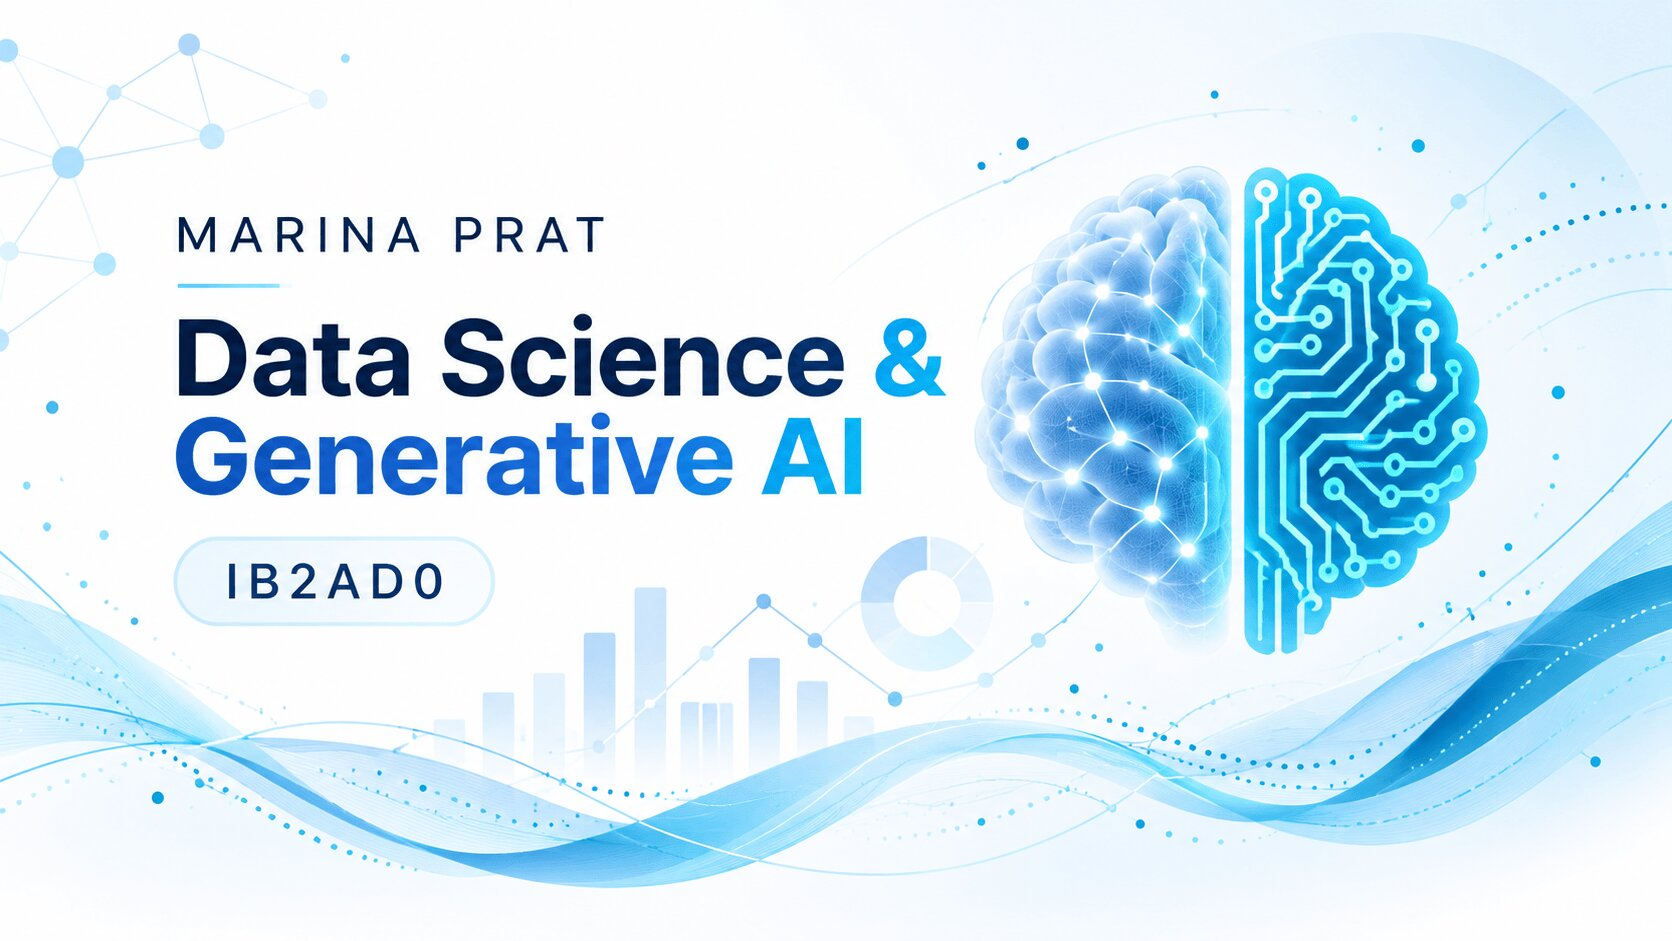

# 5.02 Modelling Hackathon
We'll get a chance in this seminar to practice for the in-class test, and also to put what we have learned into practice.

To speed things up, I have done the data/feature engineering for you, you will just need to build it into a data science model. As before, you can use the code from [GitHub](https://github.com/MJMortensonWarwick/IB2AD0_Data_Science_GenerativeAI), from the internet, and/or use the Gemini AI tools.

This is an artificial dataset, and we will be predicting if students achieve a passing grade, which we will call anything above a "D".

We'll start by importing the data:

In [2]:
from google.colab import files
upload = files.upload()

Saving students_two.csv to students_two (1).csv


Now we will get the data into Pandas and inspect it:

In [3]:
import pandas as pd
df = pd.read_csv("students_two.csv")

df.head()

,Id,Student_Age,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade
0,5001,21,Other,50%,Yes,No,Private,0,Always,Yes,Yes,No,No,AA
1,5002,20,Other,50%,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA
2,5003,21,State,50%,No,No,Private,2,Never,No,No,No,Yes,AA
3,5004,18,Private,50%,Yes,No,Bus,2,Always,No,Yes,No,No,AA
4,5005,22,Private,50%,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA


Let's check for missing values:

In [4]:
df.isnull().sum()

,0
Id,0
Student_Age,0
High_School_Type,0
Scholarship,1
Additional_Work,0
Sports_activity,0
Transportation,0
Weekly_Study_Hours,0
Attendance,0
Reading,0


Only one missing value. Let's just drop it out of laziness:

In [5]:
df.dropna(inplace=True)
df.isnull().sum()

,0
Id,0
Student_Age,0
High_School_Type,0
Scholarship,0
Additional_Work,0
Sports_activity,0
Transportation,0
Weekly_Study_Hours,0
Attendance,0
Reading,0


We have an ID column we know won't be predictive ... so let's drop it:

In [6]:
df = df.drop(["Id"], axis=1)
df.head()

,Student_Age,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade
0,21,Other,50%,Yes,No,Private,0,Always,Yes,Yes,No,No,AA
1,20,Other,50%,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA
2,21,State,50%,No,No,Private,2,Never,No,No,No,Yes,AA
3,18,Private,50%,Yes,No,Bus,2,Always,No,Yes,No,No,AA
4,22,Private,50%,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA


Next we will convert some of the text features to numbers:

In [7]:
# High school
print(df['High_School_Type'].unique())

['Other' 'State' 'Private']


We can't easily convert these to a number range. Instead we should use one-hot encoding:

In [8]:
df = pd.get_dummies(df, columns=['High_School_Type'], drop_first=True, dtype=int)
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,50%,Yes,No,Private,0,Always,Yes,Yes,No,No,AA,0,0
1,20,50%,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA,0,0
2,21,50%,No,No,Private,2,Never,No,No,No,Yes,AA,0,1
3,18,50%,Yes,No,Bus,2,Always,No,Yes,No,No,AA,1,0
4,22,50%,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA,1,0


We have converted this to two columns (on the far right) - "High_School_Type_Private" and "High_School_Type_State". We do not need the "Other" type as if the student is "Other" then both "Private" and "State" will be 0 (a unique combination). This is controlled by the command _drop\_first=True_. We also specify the data type (_dtype_) as __int__ so we return 0s and 1s rather than True and False.

Next we can look at Scholarship. It needs to be converted from a text representation of a percentage to a number:

In [9]:
df['Scholarship'] = df['Scholarship'].str.replace('%', '').astype(float) / 100
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,Yes,No,Private,0,Always,Yes,Yes,No,No,AA,0,0
1,20,0.5,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA,0,0
2,21,0.5,No,No,Private,2,Never,No,No,No,Yes,AA,0,1
3,18,0.5,Yes,No,Bus,2,Always,No,Yes,No,No,AA,1,0
4,22,0.5,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA,1,0


"Additional_Work" is next:

In [10]:
# Additional work
print(df['Additional_Work'].unique())

['Yes' 'No']


Two values, so we can convert to 0 and 1:

In [11]:
df['Additional_Work'] = df['Additional_Work'].map({'Yes': 1, 'No': 0})
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,No,Private,0,Always,Yes,Yes,No,No,AA,0,0
1,20,0.5,1,No,Private,0,Always,Yes,No,Yes,Yes,AA,0,0
2,21,0.5,0,No,Private,2,Never,No,No,No,Yes,AA,0,1
3,18,0.5,1,No,Bus,2,Always,No,Yes,No,No,AA,1,0
4,22,0.5,0,No,Bus,12,Always,Yes,No,Yes,Yes,AA,1,0


Let's speed up now:

In [12]:
categorical_cols = ['Sports_activity', 'Transportation', 'Attendance', 'Reading', 'Notes', 'Listening_in_Class', 'Project_work', 'Grade']

for col in categorical_cols:
    print(f"Unique values for '{col}': {df[col].unique()}")

Unique values for 'Sports_activity': ['No' 'Yes']
Unique values for 'Transportation': ['Private' 'Bus']
Unique values for 'Attendance': ['Always' 'Never' 'Sometimes' '3']
Unique values for 'Reading': ['Yes' 'No']
Unique values for 'Notes': ['Yes' 'No' '6']
Unique values for 'Listening_in_Class': ['No' 'Yes' '6']
Unique values for 'Project_work': ['No' 'Yes']
Unique values for 'Grade': ['AA' 'BA' 'CC' 'Fail' 'BB' 'CB' 'DD' 'DC']


The values of '6' in 'Notes' and 'Listening_in_Class' make no sense, and neither do '3' for 'Attendance'. We'll be lazy and drop these rows (really we should check with an SME):

In [14]:
df = df[(df['Notes'] != '6') & (df['Listening_in_Class'] != '6') & (df['Attendance'] != '3')]
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,No,Private,0,Always,Yes,Yes,No,No,AA,0,0
1,20,0.5,1,No,Private,0,Always,Yes,No,Yes,Yes,AA,0,0
2,21,0.5,0,No,Private,2,Never,No,No,No,Yes,AA,0,1
3,18,0.5,1,No,Bus,2,Always,No,Yes,No,No,AA,1,0
4,22,0.5,0,No,Bus,12,Always,Yes,No,Yes,Yes,AA,1,0


Now we can convert all those "Yes" / "No" columns to 0 and 1.

In [16]:
binary_cols = ['Sports_activity', 'Reading', 'Notes', 'Listening_in_Class', 'Project_work']

for col in binary_cols:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,NaN,Private,0,Always,NaN,NaN,NaN,NaN,AA,0,0
1,20,0.5,1,NaN,Private,0,Always,NaN,NaN,NaN,NaN,AA,0,0
2,21,0.5,0,NaN,Private,2,Never,NaN,NaN,NaN,NaN,AA,0,1
3,18,0.5,1,NaN,Bus,2,Always,NaN,NaN,NaN,NaN,AA,1,0
4,22,0.5,0,NaN,Bus,12,Always,NaN,NaN,NaN,NaN,AA,1,0


We can also do this with "Transportation":

In [17]:
df['Transportation'] = df['Transportation'].map({'Private': 1, 'Bus': 0})
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,NaN,1,0,Always,NaN,NaN,NaN,NaN,AA,0,0
1,20,0.5,1,NaN,1,0,Always,NaN,NaN,NaN,NaN,AA,0,0
2,21,0.5,0,NaN,1,2,Never,NaN,NaN,NaN,NaN,AA,0,1
3,18,0.5,1,NaN,0,2,Always,NaN,NaN,NaN,NaN,AA,1,0
4,22,0.5,0,NaN,0,12,Always,NaN,NaN,NaN,NaN,AA,1,0


For Attendance an ordinal range makes sense:

In [18]:
df['Attendance'] = df['Attendance'].map({'Never': 0, 'Sometimes': 1, 'Always': 2})
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,NaN,1,0,2,NaN,NaN,NaN,NaN,AA,0,0
1,20,0.5,1,NaN,1,0,2,NaN,NaN,NaN,NaN,AA,0,0
2,21,0.5,0,NaN,1,2,0,NaN,NaN,NaN,NaN,AA,0,1
3,18,0.5,1,NaN,0,2,2,NaN,NaN,NaN,NaN,AA,1,0
4,22,0.5,0,NaN,0,12,2,NaN,NaN,NaN,NaN,AA,1,0


This just leaves the target - 'Grade'. To make the problem binary we'll convert 'Fail' and any grade that includes a 'D' as 0 (for fail) and the rest as 1 (pass):

In [19]:
df['Grade'] = df['Grade'].apply(lambda x: 0 if x == 'Fail' or 'D' in x else 1)
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,NaN,1,0,2,NaN,NaN,NaN,NaN,1,0,0
1,20,0.5,1,NaN,1,0,2,NaN,NaN,NaN,NaN,1,0,0
2,21,0.5,0,NaN,1,2,0,NaN,NaN,NaN,NaN,1,0,1
3,18,0.5,1,NaN,0,2,2,NaN,NaN,NaN,NaN,1,1,0
4,22,0.5,0,NaN,0,12,2,NaN,NaN,NaN,NaN,1,1,0


The code has a new function `lambda`. A lambda function in Python is a small, anonymous function. It's defined using the `lambda` keyword and can take any number of arguments, but can only have one expression. The expression is evaluated and returned. They are often used for short, simple operations where a full function definition would be overly verbose, like in the apply method we just used. Although the function is new, the actual mechanics are quite simple. If the data is "Fail" or contains "D" return 0, and else return 1.

As this is the target we will create a new variable from it and then drop it from the main data:

In [20]:
Y_values = df[['Grade']].values.ravel() # change to list

Y_values

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 0, 0, 1, 1, 1, 1, 1])

In [21]:
X_values = df.drop(['Grade'], axis=1)
X_values.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,NaN,1,0,2,NaN,NaN,NaN,NaN,0,0
1,20,0.5,1,NaN,1,0,2,NaN,NaN,NaN,NaN,0,0
2,21,0.5,0,NaN,1,2,0,NaN,NaN,NaN,NaN,0,1
3,18,0.5,1,NaN,0,2,2,NaN,NaN,NaN,NaN,1,0
4,22,0.5,0,NaN,0,12,2,NaN,NaN,NaN,NaN,1,0


We can now scale X:

In [22]:
from sklearn.preprocessing import MinMaxScaler

# create a MinMaxScaler object
scaler = MinMaxScaler()

# fit and transform the data and convert back to DataFrame
X_values = pd.DataFrame(scaler.fit_transform(X_values), columns=X_values.columns)
X_values

/usr/local/lib/python3.13/dist-packages/sklearn/utils/_array_api.py:776: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmin(X, axis=axis))
/usr/local/lib/python3.13/dist-packages/sklearn/utils/_array_api.py:793: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmax(X, axis=axis))


,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,High_School_Type_Private,High_School_Type_State
0,0.375,0.333333,1.0,NaN,1.0,0.000000,1.0,NaN,NaN,NaN,NaN,0.0,0.0
1,0.250,0.333333,1.0,NaN,1.0,0.000000,1.0,NaN,NaN,NaN,NaN,0.0,0.0
2,0.375,0.333333,0.0,NaN,1.0,0.166667,0.0,NaN,NaN,NaN,NaN,0.0,1.0
3,0.000,0.333333,1.0,NaN,0.0,0.166667,1.0,NaN,NaN,NaN,NaN,1.0,0.0
4,0.500,0.333333,0.0,NaN,0.0,1.000000,1.0,NaN,NaN,NaN,NaN,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
135,0.500,0.333333,1.0,NaN,1.0,0.000000,1.0,NaN,NaN,NaN,NaN,0.0,1.0
136,0.000,0.666667,0.0,NaN,1.0,0.000000,0.0,NaN,NaN,NaN,NaN,0.0,1.0
137,0.000,0.666667,0.0,NaN,1.0,0.000000,1.0,NaN,NaN,NaN,NaN,1.0,0.0
138,0.500,0.666667,1.0,NaN,0.0,1.000000,0.5,NaN,NaN,NaN,NaN,0.0,1.0


And now we can split into training and test:

In [23]:
# split data into training and test
from sklearn.model_selection  import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X_values, Y_values, test_size = 0.2, random_state=1984, stratify=Y_values)

# print the shapes to check everything is OK
print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

(112, 13)
(28, 13)
(112,)
(28,)


And now its time for modelling ...



Your turn :)

In [25]:
import pandas as pd

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (140, 14)

Columns:
['Student_Age', 'Scholarship', 'Additional_Work', 'Sports_activity', 'Transportation', 'Weekly_Study_Hours', 'Attendance', 'Reading', 'Notes', 'Listening_in_Class', 'Project_work', 'Grade', 'High_School_Type_Private', 'High_School_Type_State']


,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,NaN,1,0,2,NaN,NaN,NaN,NaN,1,0,0
1,20,0.5,1,NaN,1,0,2,NaN,NaN,NaN,NaN,1,0,0
2,21,0.5,0,NaN,1,2,0,NaN,NaN,NaN,NaN,1,0,1
3,18,0.5,1,NaN,0,2,2,NaN,NaN,NaN,NaN,1,1,0
4,22,0.5,0,NaN,0,12,2,NaN,NaN,NaN,NaN,1,1,0


We'll use an 80/20 train/test split. Replace TARGET_COLUMN with the column your professor wants you to predict.

In [28]:
from sklearn.model_selection import train_test_split

# Replace with the real target column name
target_column = "TARGET_COLUMN"

X = df.drop(columns=[target_column])
y = df[target_column]

# Remove observations with missing target values
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", X_train.shape)
print("Testing observations:", X_test.shape)

Training observations: (112, 13)
Testing observations: (28, 13)


In [29]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score, recall_score
import pandas as pd

# Identify numerical and categorical columns
numeric_cols = X.select_dtypes(include="number").columns
categorical_cols = X.select_dtypes(exclude="number").columns

# Preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore",
                             sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

# Define the models
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, random_state=42
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42
    )
}

results = []

# Train and evaluate every model
for name, algorithm in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", algorithm)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results)
display(results_df.sort_values("Macro F1", ascending=False))

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Sports_activity' 'Reading' 'Notes' 'Listening_in_Class' 'Project_work']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Sports_activity' 'Reading' 'Notes' 'Listening_in_Class' 'Project_work']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Sports_activity' 'Reading' 'Notes' 'Listening_in_Class' 'Project_work']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping featur

,Model,Accuracy,Macro F1,Macro Recall
0,Decision Tree,0.714286,0.619048,0.619048
1,Random Forest,0.678571,0.590244,0.595238
2,Gradient Boosting,0.678571,0.590244,0.595238
3,Logistic Regression,0.678571,0.404255,0.452381


Decision Tree is currently the best-performing model, because it achieves the highest scores across all three metrics.

Interestingly, Random Forest and Gradient Boosting produce exactly the same scores. This doesn't necessarily mean their predictions are identical, only that their aggregated evaluation metrics are equal.

Logistic Regression has a similar accuracy to Random Forest and Gradient Boosting, but a much lower Macro F1. This suggests that its performance is less balanced across the different classes.

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Sports_activity' 'Reading' 'Notes' 'Listening_in_Class' 'Project_work']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Sports_activity' 'Reading' 'Notes' 'Listening_in_Class' 'Project_work']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


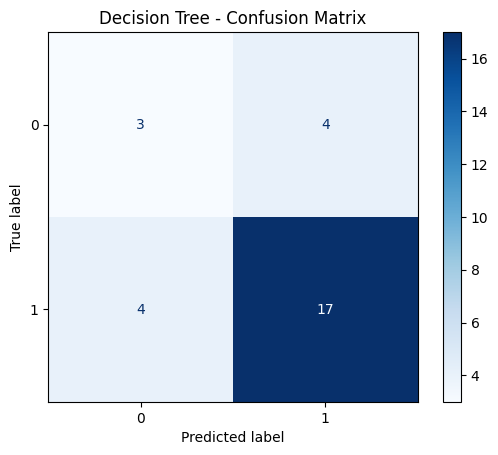

In [30]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Train the Decision Tree using the same preprocessing
best_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DecisionTreeClassifier(max_depth=5, random_state=42))
])

best_pipeline.fit(X_train, y_train)

# Predictions
y_pred = best_pipeline.predict(X_test)

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    cmap="Blues"
)

plt.title("Decision Tree - Confusion Matrix")
plt.show()

Best parameters: {'model__max_depth': 3, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2}
Best CV Macro F1: 0.6913712202801388
              precision    recall  f1-score   support

           0       0.43      0.43      0.43         7
           1       0.81      0.81      0.81        21

    accuracy                           0.71        28
   macro avg       0.62      0.62      0.62        28
weighted avg       0.71      0.71      0.71        28



/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Sports_activity' 'Reading' 'Notes' 'Listening_in_Class' 'Project_work']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Sports_activity' 'Reading' 'Notes' 'Listening_in_Class' 'Project_work']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


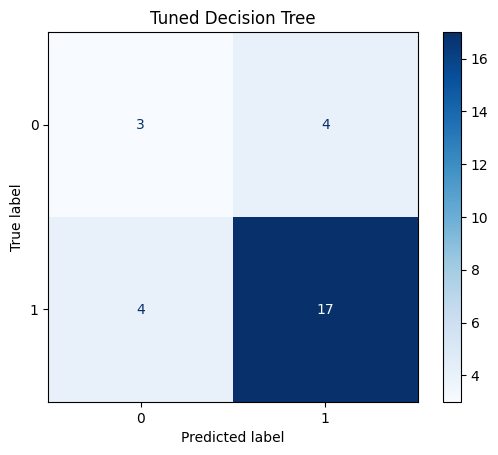

In [31]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Decision Tree pipeline
tree_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])

# Hyperparameters to test
parameters = {
    "model__max_depth": [2, 3, 4, 5, 8, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

# Cross-validation
grid_search = GridSearchCV(
    tree_pipeline,
    parameters,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV Macro F1:", grid_search.best_score_)

# Evaluate the selected model
best_tree = grid_search.best_estimator_
y_pred_tuned = best_tree.predict(X_test)

print(classification_report(y_test, y_pred_tuned))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_tuned,
    cmap="Blues"
)

plt.title("Tuned Decision Tree")
plt.show()

Confusion Matrix Interpretation

The Decision Tree correctly classified 20 out of 28 observations, achieving an accuracy of 71.43%. However, the model performed better on class 1 (80.95% recall) than on class 0 (42.86% recall). This shows why accuracy alone can be misleading when classes are imbalanced.

Hyperparameter tuning with GridSearchCV can help identify a better model configuration using cross-validation, reducing the risk of overfitting.